# Joint beam + sky solver (rewrite)

**What changed.** The old notebook alternated *sky solve -> freeze -> fit beam*, with a positivity clip in between. That is replaced by one objective in the beam-error coefficients `p` alone:

    -log P(y | p) = 0.5 y^T C(p)^-1 y + 0.5 log det C(p),     C = A(p) S A(p)^T + N

i.e. the sky is **integrated out analytically** (Gaussian prior `S`, noise `N`), not frozen, not clipped, not optimised. Nothing is handed from one block to the next, so there is no step where deconvolution can absorb the beam error before the beam sees it.

**Why marginalise rather than literally optimise sky and beam together.** On a synthetic problem with the same structure, jointly maximising over (sky, p) did *worse than doing nothing* whenever the sky has more unknowns than there are data, which is the regime here (about 16,600 packed sky parameters per frequency against 10,000 samples). Marginalising the sky fixed that. See the chat summary for the numbers.

**Memory.** The sky is band-limited to `LFIT` (chosen from a printed table), the data are subsampled in time, and every big array is passed to the compiled functions as an argument instead of being closed over. No full-resolution CG solves, no NUTS chains. The `p`-dependence of the visibility normalisation is precomputed (and verified linear) rather than recomputed through the spherical-harmonic transform.

**Run order.** Cells 1-10 are your setup, unchanged (old cells for the alternating loops, NUTS, whitening and the Wiener-quality detours are removed; the previous notebook is untouched). Then the six solver cells in order. **Run the self-test cell and confirm all four PASS before reading anything after it.**

**What is *not* validated.** The solver cells were tested only on a synthetic stand-in for your arrays (numpy, tiny sizes). They have not been run on your real data or in JAX. The checks inside the self-test cell are what tell you whether they hold there.


In [1]:
import jax

jax.config.update("jax_enable_x64", True)
jax.config.update(
    "jax_platform_name", "cpu"
)  # Change to "gpu" if running on a cluster
import jax.numpy as jnp
import jax.scipy.sparse.linalg as jsp_linalg
import jaxopt

print("JAX devices:", jax.devices())
print("Default backend:", jax.default_backend())

JAX devices: [CpuDevice(id=0)]
Default backend: cpu


In [2]:
from concurrent.futures import ProcessPoolExecutor
from functools import partial
import itertools
import time

import astropy
import astropy.units as u
import corner  # pip install corner (for the posterior plots)
import croissant as cro
import croissant.jax as crojax
import healpy as hp
import lunarsky
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
from healpy import Alm, get_nside, projview, ud_grade
from numpyro.infer import MCMC, NUTS
import s2fft
from tqdm.notebook import tqdm

/usr/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
/usr/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


In [3]:
def create_perturbed_base_map(
    base_pixel_map, lmax, nside, amp_scale=1.10, phase_shift_deg=5.0
):
  """Takes a 1D pixel map, converts it to 2D s2fft ALMs, applies a

  consistent phase/amplitude perturbation, and returns the modified pixel map.
  """
  # Forward SHT to get into 2D s2fft ALM space
  beam2alm = partial(
      s2fft.forward_jax,
      L=lmax + 1,
      spin=0,
      nside=nside,
      sampling="healpix",
      reality=True,
  )
  clean_alms = beam2alm(jnp.array(base_pixel_map))

  # Apply the complex phase and amplitude shift
  phase_rad = np.radians(phase_shift_deg)
  perturbation_factor = amp_scale * np.exp(1j * phase_rad)
  perturbed_alms = clean_alms * perturbation_factor

  # Inverse SHT to turn it back into a valid HEALPix pixel map
  alm2beam = partial(
      s2fft.inverse_jax,
      L=lmax + 1,
      spin=0,
      nside=nside,
      sampling="healpix",
      reality=True,
  )
  perturbed_map = alm2beam(perturbed_alms).real

  return np.asarray(perturbed_map)


def rotate_bowtie(bowtie_beam, elaz):
  el, az = elaz
  angle_1 = (0, 0, el)
  angle_2 = (az, 0, 0)
  rotator_1 = hp.rotator.Rotator(rot=angle_1)
  rotator_2 = hp.rotator.Rotator(rot=angle_2)
  rotator = rotator_1 * rotator_2
  rotated_bowtie_beam = np.empty(bowtie_beam.shape)
  for i, beam in enumerate(bowtie_beam):
    rotated_bowtie_beam[i] = rotator.rotate_map_alms(beam)
  return rotated_bowtie_beam


# Load Beams
bowtie = np.load("eigsep_bowtie_v000.npz")
vivaldi = np.load("eigsep_vivaldi.npz")

# --- FIX #7: check how many frequency channels are actually available ---
# before committing to a range. The SVD below runs on the FULL bowtie["bm"]
# (all channels) regardless of FREQ_START/FREQ_END, so widening the range
# below does NOT require recomputing it.
print(f"bowtie['bm'] shape (n_freq_total, npix): {bowtie['bm'].shape}")
print(f"vivaldi['freqs'] shape: {vivaldi['freqs'].shape}")
try:
  _gsm_shape_check = np.load("gsm_model.npy").shape
  print(f"gsm_model.npy shape (n_freq_total, npix): {_gsm_shape_check}")
except Exception as _e:
  print(f"(could not pre-check gsm_model.npy shape: {_e})")

# SVD the bowtie beam (full_matrices=False saves ~19 GB of RAM!)
u_svd, s_svd, v_svd = np.linalg.svd(bowtie["bm"], full_matrices=False)
print(f"SVD computed safely! U shape: {u_svd.shape}, V shape: {v_svd.shape}")

# Frequency Indices
# FIX #7: widened from a single channel (was FREQ_START=6, FREQ_END=7) so
# the same 5 beam-error coefficients must explain MULTIPLE frequencies'
# visibilities jointly - a coincidental single-frequency fit has no reason
# to also satisfy a second, independently-generated frequency's data, while
# a real beam defect (frequency-smooth) should. ADJUST THESE two numbers
# based on the shapes printed just above - this default (8 channels
# centered near the original single channel) is a starting guess, not a
# verified-safe range for your actual data.
FREQ_START = 2
FREQ_END = 4     # N_FREQS=2. The new solver is cheap per extra channel; widen once this runs.
N_FREQS = FREQ_END - FREQ_START
freq = vivaldi["freqs"][FREQ_START:FREQ_END]
nside = vivaldi["nside"].item()
lmax = 2 * nside
npix = bowtie["bm"].shape[-1]

# --- CREATE THE PERTURBED BASE MAP WITH POWER CONSERVATION ---
base_bowtie_multi_TRUE = bowtie["bm"][FREQ_START:FREQ_END]
base_bowtie_multi_PERTURBED = np.zeros_like(base_bowtie_multi_TRUE)

# We need the true total power to anchor our normalization
beam2alm = partial(
    s2fft.forward_jax,
    L=lmax + 1,
    spin=0,
    nside=nside,
    sampling="healpix",
    reality=True,
)

for f in range(N_FREQS):
  # 1. Calculate the total power (norm) of the clean base beam
  clean_alms = beam2alm(jnp.array(base_bowtie_multi_TRUE[f]))
  true_power = crojax.alm.total_power(clean_alms, lmax)

  # 2. Generate the raw perturbed map (introduces the 5-degree phase warp)
  raw_perturbed_map = create_perturbed_base_map(
      base_bowtie_multi_TRUE[f],
      lmax,
      nside,
      amp_scale=1.10,  # Keeps your 10% amplitude structure
      phase_shift_deg=5.0,  # Keeps your 5-degree phase distortion
  )

  # 3. Calculate the power of this new perturbed map
  perturbed_alms_raw = beam2alm(jnp.array(raw_perturbed_map))
  perturbed_power_raw = crojax.alm.total_power(perturbed_alms_raw, lmax)

  # 4. Enforce power conservation!
  # Scale the map so its total integrated power exactly matches the true universe beam
  u_scale = jnp.sqrt(true_power / perturbed_power_raw)
  base_bowtie_multi_PERTURBED[f] = raw_perturbed_map * u_scale

print("Power-conserving perturbed base beam created successfully!")

bowtie['bm'] shape (n_freq_total, npix): (202, 49152)
vivaldi['freqs'] shape: (201,)
gsm_model.npy shape (n_freq_total, npix): (50, 49152)
SVD computed safely! U shape: (202, 202), V shape: (202, 49152)
Power-conserving perturbed base beam created successfully!


In [4]:
# --- ROTATE BOTH THROUGH THE 20 POINTINGS ---
elaz_pointings = [(float(el), 0.0) for el in np.linspace(0, 90, 20)]

rotated_bowties_TRUE = []
rotated_bowties_PERTURBED = []

for elaz in tqdm(elaz_pointings, desc="Rotating beams"):
  # 1. Rotate the clean base beam across all 20 pointings
  rotated_bowties_TRUE.append(rotate_bowtie(base_bowtie_multi_TRUE, elaz))

  # 2. Rotate the flawed base beam across the exact same 20 pointings
  # Every single pointing now inherits the exact same physical distortion!
  rotated_bowties_PERTURBED.append(
      rotate_bowtie(base_bowtie_multi_PERTURBED, elaz)
  )

# Combine and mask the back-lobes (npix//2)
beams_true_f = jnp.array(np.stack(rotated_bowties_TRUE)).at[..., npix // 2 :].set(0)
beams_pert_f = jnp.array(np.stack(rotated_bowties_PERTURBED)).at[..., npix // 2 :].set(0)

# --- FINAL STEP: RUN SHT TO GET YOUR DOWNSTREAM ARRAYS ---
beam_alms_TRUE = []
beam_alms_PERTURBED = []
norms_TRUE = []
norms_PERTURBED = []

beam2alm = partial(
    s2fft.forward_jax,
    L=lmax + 1,
    spin=0,
    nside=nside,
    sampling="healpix",
    reality=True,
)

for b_idx in tqdm(range(beams_true_f.shape[0]), desc="Final SHT on Beams"):
  # SHT and Norms on True (for generating y_true data)
  alm_t = jax.vmap(beam2alm)(beams_true_f[b_idx])
  norm_t = jax.vmap(lambda x: crojax.alm.total_power(x, lmax))(alm_t)

  # SHT and Norms on Perturbed (for your Wiener Filter / MCMC guesses)
  alm_p = jax.vmap(beam2alm)(beams_pert_f[b_idx])
  norm_p = jax.vmap(lambda x: crojax.alm.total_power(x, lmax))(alm_p)

  beam_alms_TRUE.append(alm_t)
  beam_alms_PERTURBED.append(alm_p)
  norms_TRUE.append(norm_t)
  norms_PERTURBED.append(norm_p)

# Convert to final JAX Tensors
beam_alms_TRUE = jnp.array(beam_alms_TRUE)  # Shape: (B, F, L, M)
beam_alms_PERTURBED = jnp.array(beam_alms_PERTURBED)  # Shape: (B, F, L, M)
norms_TRUE = jnp.array(norms_TRUE)  # Shape: (B, F)
norms_PERTURBED = jnp.array(norms_PERTURBED)  # Shape: (B, F)

Rotating beams:   0%|          | 0/20 [00:00<?, ?it/s]

Final SHT on Beams:   0%|          | 0/20 [00:00<?, ?it/s]

In [5]:
ntimes = 500
world = "earth"

dt_sim = cro.constants.sidereal_day[world] / ntimes
phases = crojax.simulator.rot_alm_z(lmax, ntimes, dt_sim, world=world)

time_obs = astropy.time.Time("2025-12-01 09:00:00")
loc = astropy.coordinates.EarthLocation(lat=39.2477, lon=-113.4033)
topo = astropy.coordinates.AltAz(obstime=time_obs, location=loc)

eul_topo, dl_topo = crojax.rotations.generate_euler_dl(lmax, topo, "fk5")
eul_gal, dl_gal = crojax.rotations.generate_euler_dl(lmax, "galactic", "fk5")

topo2fk5 = partial(
    s2fft.utils.rotation.rotate_flms,
    L=lmax + 1,
    rotation=eul_topo,
    dl_array=dl_topo,
)
gal2fk5 = partial(
    s2fft.utils.rotation.rotate_flms,
    L=lmax + 1,
    rotation=eul_gal,
    dl_array=dl_gal,
)


def load_true_sky(realistic=False):
  sky_L = lmax + 1
  sky_nside = sky_L // 2
  if realistic:
    # --- FIX #8: gsm_model.npy is offset by -1 relative to bowtie/vivaldi's
    # frequency indexing (gsm_model[0] corresponds to bowtie/vivaldi index 1;
    # bowtie has one extra channel at the END that vivaldi/gsm_model don't
    # have). Without this offset, the sky and beam at "the same" FREQ_START:
    # FREQ_END index actually come from ADJACENT, not matching, physical
    # frequencies - which would undermine the multi-frequency degeneracy
    # test specifically (it relies on sky and beam being evaluated at truly
    # corresponding frequencies to expose their different spectral behavior).
    GSM_FREQ_START = FREQ_START - 1
    GSM_FREQ_END = FREQ_END - 1
    if GSM_FREQ_START < 0:
      raise ValueError(
          f"FREQ_START={FREQ_START} has no gsm_model.npy counterpart "
          f"(would need index {GSM_FREQ_START} < 0) - bowtie/vivaldi index 0 "
          f"has no matching sky channel. Use FREQ_START >= 1."
      )
    print(
        f"Sky (gsm_model.npy) channels {GSM_FREQ_START}:{GSM_FREQ_END} <-> "
        f"beam (bowtie/vivaldi) channels {FREQ_START}:{FREQ_END}"
    )
    # Load the full map from disk, but slice to the selected frequency batch immediately
    sky_map = np.load("gsm_model.npy")[GSM_FREQ_START:GSM_FREQ_END]
    original_nside = get_nside(sky_map[0])
    if sky_nside != original_nside:
      sky_map = ud_grade(sky_map, sky_nside)
    sky_map = jnp.array(sky_map)
    sky2alm = partial(
        s2fft.forward_jax,
        L=sky_L,
        spin=0,
        nside=sky_nside,
        sampling="healpix",
        reality=True,
    )
    sky_alm = jax.vmap(sky2alm)(sky_map)
    sky_alm = jax.vmap(gal2fk5)(sky_alm)
    return sky_alm
  else:
    return jnp.zeros((N_FREQS, lmax + 1, 2 * lmax + 1), dtype=jnp.complex128)


# Load the true celestial sky for our specific frequency batch
true_sky_alm = load_true_sky(realistic=True)


# =====================================================================
# ROTATE BOTH TRUE AND PERTURBED BEAMS TO FK5
# =====================================================================

# 1. Rotate the TRUE beams to FK5 (Used downstream to generate y_true)
beam_alms_TRUE_transformed = []
for b_idx in tqdm(
    range(beam_alms_TRUE.shape[0]), desc="Rotating True Beams to FK5"
):
  beam_alm_rot = jax.vmap(topo2fk5)(beam_alms_TRUE[b_idx])  # vmap across Freqs
  beam_alms_TRUE_transformed.append(beam_alm_rot)
beam_alms_TRUE_transformed = jnp.array(beam_alms_TRUE_transformed)  # (B, F, L, M)


# 2. Rotate the PERTURBED starting guess beams to FK5 (Used in Wiener Filter / MCMC)
beam_alms_PERTURBED_transformed = []
for b_idx in tqdm(
    range(beam_alms_PERTURBED.shape[0]), desc="Rotating Perturbed Beams to FK5"
):
  beam_alm_rot = jax.vmap(topo2fk5)(
      beam_alms_PERTURBED[b_idx]
  )  # vmap across Freqs
  beam_alms_PERTURBED_transformed.append(beam_alm_rot)
beam_alms_PERTURBED_transformed = jnp.array(
    beam_alms_PERTURBED_transformed
)  # (B, F, L, M)


# Clean up unneeded instrument-frame variables to free RAM
del beam_alms_TRUE, beam_alms_PERTURBED

Sky (gsm_model.npy) channels 1:3 <-> beam (bowtie/vivaldi) channels 2:4


Rotating True Beams to FK5:   0%|          | 0/20 [00:00<?, ?it/s]

Rotating Perturbed Beams to FK5:   0%|          | 0/20 [00:00<?, ?it/s]

In [6]:
twod_shape = (lmax + 1, 2 * lmax + 1)
oned_shape = 2 * Alm.getsize(lmax) - (lmax + 1)


def _build_alm_indices(lmax):
  rows, cols_pos, cols_neg, signs = [], [], [], []
  for m in range(1, lmax + 1):
    for l in range(m, lmax + 1):
      rows.append(l)
      cols_pos.append(lmax + m)
      cols_neg.append(lmax - m)
      signs.append((-1.0) ** m)
  return (
      jnp.array(rows),
      jnp.array(cols_pos),
      jnp.array(cols_neg),
      jnp.array(signs),
  )


_alm_rows, _alm_cols_pos, _alm_cols_neg, _alm_signs = _build_alm_indices(lmax)
_N_pos_m = len(_alm_rows)


def _unpack_single_freq(x_freq, lmax):
  m0_real = x_freq[: lmax + 1]
  pos_m_real = x_freq[lmax + 1 : lmax + 1 + _N_pos_m]
  pos_m_imag = x_freq[lmax + 1 + _N_pos_m :]
  pos_m_complex = (1 / jnp.sqrt(2)) * (pos_m_real + 1j * pos_m_imag)
  flm = jnp.zeros((lmax + 1, 2 * lmax + 1), dtype=jnp.complex128)
  flm = flm.at[:, lmax].set(m0_real + 0j, unique_indices=True)
  flm = flm.at[_alm_rows, _alm_cols_pos].set(
      pos_m_complex, unique_indices=True
  )
  flm = flm.at[_alm_rows, _alm_cols_neg].set(
      _alm_signs * jnp.conj(pos_m_complex), unique_indices=True
  )
  return flm


def _pack_single_freq(flm_freq, lmax):
  m0_real = jnp.real(flm_freq[:, lmax])
  pos_m_complex = jnp.sqrt(2) * flm_freq[_alm_rows, _alm_cols_pos]
  return jnp.concatenate(
      [m0_real, jnp.real(pos_m_complex), jnp.imag(pos_m_complex)]
  )


def s2fft_unravel(x_real, lmax):
  N_per_freq = (lmax + 1) ** 2
  x_reshaped = jnp.ravel(x_real).reshape(-1, N_per_freq)
  return jax.vmap(_unpack_single_freq, in_axes=(0, None))(x_reshaped, lmax)


def s2fft_ravel(flm_s2fft):
  L = flm_s2fft.shape[1]
  lmax = L - 1
  return jnp.ravel(
      jax.vmap(_pack_single_freq, in_axes=(0, None))(flm_s2fft, lmax)
  )

In [7]:
total_beam_num = beam_alms_TRUE_transformed.shape[0]


@jax.jit
def forward_true_universe(x_flat):
  """Generates mock data using the physically real, clean beams."""
  sky_alm_multi = s2fft_unravel(x_flat, lmax)
  vis = jnp.einsum(
      "flm,tm,bflm->ftb",
      sky_alm_multi,
      phases.conjugate(),
      beam_alms_TRUE_transformed,
  )
  vis = vis.real / norms_TRUE.T[:, None, :]
  return vis.ravel()


# Generate your mock observed data from the true sky
x_true_flat = s2fft_ravel(true_sky_alm)
y_true = forward_true_universe(x_true_flat)


@jax.jit
def forward_perturbed_model(x_flat):
  """Used by the CG solver. Assumes the instrument has the 10% flaw."""
  sky_alm_multi = s2fft_unravel(x_flat, lmax)
  vis = jnp.einsum(
      "flm,tm,bflm->ftb",
      sky_alm_multi,
      phases.conjugate(),
      beam_alms_PERTURBED_transformed,
  )
  vis = vis.real / norms_PERTURBED.T[:, None, :]
  return vis.ravel()


# Setup the Adjoint operations specifically for the perturbed starting guess model
_x0_multi = jnp.zeros(N_FREQS * oned_shape)
_adjoint_fn_perturbed = jax.linear_transpose(
    forward_perturbed_model, _x0_multi
)


@jax.jit
def adjoint_perturbed(y_flat):
  return _adjoint_fn_perturbed(y_flat)[0]


# FIX #10: freq (vivaldi["freqs"]) is already in Hz (e.g. 52000000.0), so
# multiplying by 1e6 here double-converts, inflating df by 6 orders of
# magnitude and crushing thermal_sigma toward zero. At N_FREQS=1 this
# branch never ran (len(freq)==1 always took the 1e6 fallback, which
# happens to already be correct), so the bug was invisible until
# N_FREQS>1 was tried.
df = (freq[1] - freq[0]) if len(freq) > 1 else 1e6
times_jd = time_obs.jd + np.arange(ntimes) * dt_sim
dt = (times_jd[1] - times_jd[0]) * 24 * 3600

# Base thermal noise
noise_scale_factor = jnp.mean(jnp.abs(y_true))
thermal_sigma = noise_scale_factor / jnp.sqrt(df * dt)

# ADD A MODEL UNCERTAINTY FLOOR
# Since our beam has a 10% / 5-degree flaw, we must add a regularization
# floor (e.g., 15% of the visibility amplitude) to absorb the geometric mismatch.
model_uncertainty = 0.005 * jnp.abs(y_true)
effective_sigma = jnp.sqrt(thermal_sigma**2 + model_uncertainty**2)

Ndiag = effective_sigma**2

In [8]:
def almtohp(alm, lmax):
  alm_m0 = alm[: lmax + 1]
  N = len(alm) - len(alm_m0)
  alm_real = alm[lmax + 1 : lmax + 1 + N // 2]
  alm_imag = alm[lmax + 1 + N // 2 :]
  alm_c = 1 / jnp.sqrt(2) * (alm_real + 1j * alm_imag)
  hp_alm = jnp.concatenate((alm_m0, alm_c), dtype=complex)
  return hp_alm


# 1. Define the pixel integration area weight
omega_pix = 4.0 * jnp.pi / (12 * nside**2)

# --- S_diag Construction with Correct Variance Scaling ---
l_indices_m0 = jnp.arange(lmax + 1)
l_indices_mgt0 = jnp.concatenate(
    [jnp.arange(m, lmax + 1) for m in range(1, lmax + 1)]
)

all_s_diagonals = []
for i in range(N_FREQS):
  single_freq_sky = true_sky_alm[i : i + 1]
  ra_single = s2fft_ravel(single_freq_sky)
  true_hp = almtohp(ra_single, lmax)
  _cl_i = hp.alm2cl(np.asarray(true_hp))

  # Divide m > 0 components by 2.0 so total power Var(u) + Var(v) = C_l
  s_diag_i = jnp.concatenate([
      _cl_i[l_indices_m0],
      _cl_i[l_indices_mgt0] / 2.0,
      _cl_i[l_indices_mgt0] / 2.0,
  ])
  all_s_diagonals.append(s_diag_i)

S_diag2 = jnp.concatenate(all_s_diagonals)
peak_power = jnp.max(S_diag2)
S_diag2 = jnp.maximum(S_diag2, peak_power * 1e-4)

In [9]:
# 0. Define modes and slices from SVD outputs
N_MODES = 8
u_slice = jnp.array(u_svd[FREQ_START:FREQ_END, :N_MODES])  # (F, N_MODES)
v_slice = v_svd[:N_MODES]  # (N_MODES, NPIX)

# --- BUG FIX #2: incorporate the SVD singular values ---
# np.linalg.svd returns u_svd, s_svd, v_svd with u_svd/v_svd both unit-norm;
# without multiplying by s_svd, all N_MODES are treated as equally important
# regardless of their true weight in the beam decomposition. s_svd was
# computed where the SVD was run, but never referenced again anywhere in
# the original notebook.
s_slice = s_svd[:N_MODES]              # (N_MODES,)
v_slice = v_slice * s_slice[:, None]   # scale each spatial mode by its true SVD weight

# 1. Rotate the PCA modes for each pointing (Pure NumPy CPU)
rotated_modes_multi = []
for elaz in tqdm(elaz_pointings, desc="Rotating PCA modes"):
  rotated_modes_multi.append(rotate_bowtie(v_slice, elaz))

# Stack into a standard NumPy host array and zero out second half
modes_f = np.stack(rotated_modes_multi)  # Shape: (B, N_MODES, NPIX)
modes_f[..., npix // 2 :] = 0.0  # Fast, in-place NumPy zeroing

# 2. Convert PCA modes to ALMs (Pure CPU using ducc0 C-contiguous slices)
mode_alms_list = []
for b_idx in tqdm(range(modes_f.shape[0]), desc="SHT on PCA modes"):
  m_alms_k = []
  for k in range(N_MODES):
    # np.ascontiguousarray ensures C++ receives clean host memory pointers
    slice_cpu = np.ascontiguousarray(modes_f[b_idx, k])
    m_alm = s2fft.forward(
        slice_cpu,
        L=lmax + 1,
        spin=0,
        nside=nside,
        sampling="healpix",
        reality=True,
    )
    m_alms_k.append(m_alm)
  mode_alms_list.append(np.stack(m_alms_k))

mode_alms = np.stack(mode_alms_list)  # Shape: (B, N_MODES, L, M) on CPU

# 3. Rotate to FK5 fully vectorized on GPU (Zero Python loops!)
print("Vectorizing topo2fk5 across all pointings and modes...")

# Transfer CPU mode ALMs to GPU JAX array
mode_alms_jax = jnp.array(mode_alms)  # Shape: (B, N_MODES, L, M)

# Double-vmap: inner vmap handles N_MODES, outer vmap handles Pointings (B)
topo2fk5_vectorized = jax.jit(jax.vmap(jax.vmap(topo2fk5)))

# Execute all 100 rotations simultaneously in GPU memory
mode_alms_fk5 = topo2fk5_vectorized(mode_alms_jax)  # Shape: (B, N_MODES, L, M)

# 4. Construct the MCMC Mode Tensor
mode_tensor = jnp.einsum("fk, bklm -> kbflm", u_slice, mode_alms_fk5)

print(f"PCA Mode Tensor ready for MCMC! Shape: {mode_tensor.shape}")

Rotating PCA modes:   0%|          | 0/20 [00:00<?, ?it/s]

SHT on PCA modes:   0%|          | 0/20 [00:00<?, ?it/s]

Vectorizing topo2fk5 across all pointings and modes...
PCA Mode Tensor ready for MCMC! Shape: (8, 20, 2, 129, 257)


In [10]:
# =====================================================================
# SOLVER CONFIG + SHARED UTILITIES
# Everything below this point is the new solver. It only needs these globals
# from the setup cells above: lmax, ntimes, phases, mode_tensor,
# beam_alms_PERTURBED_transformed, beam_alms_TRUE_transformed, y_true, Ndiag,
# S_diag2, true_sky_alm, x_true_flat, oned_shape, N_FREQS, and the alm packing
# helpers (_alm_rows, _alm_cols_pos, s2fft_unravel).
# =====================================================================
from scipy.optimize import minimize

LFIT = 32            # band limit of the joint solve. None = auto-pick in the next cell
T_STRIDE = 2           # use every T_STRIDE-th time sample (data are heavily oversampled)
PRIOR_SIGMA_P = 5.0
BOUND_P = 100.0         # |p_k| box bound for the optimiser
N_STARTS = 2         # multi-start count for the optimiser (1 = start at zero only)
SEED = 0
INCLUDE_TAIL_NOISE = True   # add the (tiny) variance of sky modes above LFIT to the noise
LMAP = 8                    # l-range shown in the residual maps at the end

K_MODES = mode_tensor.shape[0]
B_PTG = mode_tensor.shape[1]
assert mode_tensor.shape[2] == N_FREQS
assert phases.shape == (ntimes, 2 * lmax + 1), phases.shape


def compute_norms_curr(beam_curr):
  """Per-(pointing, freq) total power of a beam alm array: (B, F, L, M) -> (B, F)."""
  return jax.vmap(jax.vmap(lambda a: crojax.alm.total_power(a, lmax)))(beam_curr)


# --- The visibility normalisation must be (affine-)linear in p for the
# --- block structure below to be exact. total_power looks like a linear
# --- functional of the alms (the monopole); verify numerically instead of assuming.
n0_pert = np.asarray(compute_norms_curr(beam_alms_PERTURBED_transformed))          # (B, F)
nk_modes = np.asarray(jax.vmap(compute_norms_curr)(mode_tensor))                   # (K, B, F)
_rng = np.random.default_rng(123)
_p_chk = 0.05 * _rng.normal(size=K_MODES)
_direct = np.asarray(compute_norms_curr(
    beam_alms_PERTURBED_transformed + jnp.tensordot(jnp.asarray(_p_chk), mode_tensor, axes=1)))
_linear = n0_pert + np.tensordot(_p_chk, nk_modes, axes=1)
_rel = np.max(np.abs(_direct - _linear)) / np.max(np.abs(_direct))
print(f"norm(p) linearity check: max relative deviation = {_rel:.2e}   (expect <1e-8)")
if _rel > 1e-6:
  raise RuntimeError(
      "crojax.alm.total_power is NOT linear in the beam alms, so the p-dependence of the "
      "visibility normalisation cannot be precomputed. Stop here and report this.")
print(f"total_power / (sqrt(4 pi) Re a_00) for beam 0, freq 0: "
      f"{n0_pert[0, 0] / (np.sqrt(4 * np.pi) * np.real(np.asarray(beam_alms_PERTURBED_transformed[0, 0, 0, lmax]))):.4f}"
      f"   (1.0 means 'normalisation = beam integral')")

mode_np = np.asarray(mode_tensor)                    # host view reused by the block builder


norm(p) linearity check: max relative deviation = 1.41e-16   (expect <1e-8)
total_power / (sqrt(4 pi) Re a_00) for beam 0, freq 0: 1.0000   (1.0 means 'normalisation = beam integral')


In [11]:
# =====================================================================
# CHOOSE THE BAND LIMIT.  The joint solve only keeps sky modes l <= LFIT.
# Modes above that leak into the data as a small extra noise; estimate how
# big that is relative to the noise already assumed, and what each choice costs.
# =====================================================================
Sfull = np.asarray(S_diag2).reshape(N_FREQS, -1)              # (F, oned_shape) packed priors
Cl_f = Sfull[:, : lmax + 1]                                    # m=0 entries are C_l (floored)
beamB = np.asarray(beam_alms_PERTURBED_transformed)            # (B, F, L, M)
Pbl = np.sum(np.abs(beamB) ** 2, axis=-1)                      # (B, F, L)  sum_m |B_lm|^2
var3 = np.asarray(Ndiag).reshape(N_FREQS, ntimes, B_PTG)       # (F, T, B)
sig_fb = np.sqrt(np.median(var3, axis=1)).T                    # (B, F) typical noise std
T_EFF = len(range(0, ntimes, T_STRIDE))


def tail_variance(lfit, b_sel=None):
  """(F, b): variance of a visibility due to sky modes l > lfit (order-of-magnitude estimate)."""
  b_sel = np.arange(B_PTG) if b_sel is None else np.asarray(b_sel)
  out = np.zeros((N_FREQS, len(b_sel)))
  for f in range(N_FREQS):
    w = 0.5 * Cl_f[f, lfit + 1:]                               # variance per real m>0 parameter ~ C_l / 2
    out[f] = np.sum(Pbl[b_sel, f, lfit + 1:] * w[None, :], axis=1) / n0_pert[b_sel, f] ** 2
  return out


print(f"{'lfit':>5} {'n_x':>6} {'A MB':>7} {'GFlop/eval':>11} {'tail/noise (median)':>20} {'(max)':>8}")
_suggest = None
_cands = [c for c in (8, 12, 16, 20, 24, 32, 40, 48, 64) if c <= lmax]
for c in _cands:
  nx = (c + 1) ** 2
  ratio = np.sqrt(tail_variance(c)).T / sig_fb
  print(f"{c:5d} {nx:6d} {B_PTG * T_EFF * nx * 8 / 1e6:7.0f} {2 * B_PTG * T_EFF * nx ** 2 / 1e9:11.1f} "
        f"{np.median(ratio):20.4f} {np.max(ratio):8.4f}")
  if _suggest is None and np.median(ratio) < 0.1 and nx <= 2500:
    _suggest = c
if LFIT is None:
  LFIT = _suggest if _suggest is not None else min(_cands[-1], 48)
  print(f"\nAuto-selected LFIT = {LFIT}  (smallest candidate whose leaked variance is <10% of the noise std).")
else:
  print(f"\nUsing user-set LFIT = {LFIT}")


 lfit    n_x    A MB  GFlop/eval  tail/noise (median)    (max)
    8     81       3         0.1               0.5178   0.5280
   12    169       7         0.3               0.3071   0.3166
   16    289      12         0.8               0.2585   0.2673
   20    441      18         1.9               0.2282   0.2361
   24    625      25         3.9               0.2054   0.2124
   32   1089      44        11.9               0.1721   0.1780
   40   1681      67        28.3               0.1484   0.1535
   48   2401      96        57.6               0.1299   0.1343
   64   4225     169       178.5               0.1017   0.1052

Using user-set LFIT = 32


In [12]:
# =====================================================================
# THE SOLVER.  For a beam-error vector p the model is  y = A(p) x + noise  with
# x ~ N(0, S) the band-limited sky. Integrating x out analytically,
#     -log P(y | p) = 0.5 y^T C^-1 y + 0.5 log det C,   C = A S A^T + N,
# evaluated through the matrix-determinant lemma in the small sky space
# (n_x = (LFIT+1)^2) -- one dense Cholesky per frequency block. p (K numbers)
# is then the ONLY thing that is optimised; the sky is never frozen or clipped.
# Big arrays are passed as ARGUMENTS (never closed over), so XLA does not
# bake / duplicate them as compile-time constants.
# =====================================================================
def make_index_sets(lfit):
  rows, mm = [], []
  for m in range(1, lfit + 1):
    for l in range(m, lfit + 1):
      rows.append(l)
      mm.append(m)
  rows = np.array(rows, dtype=int)
  mm = np.array(mm, dtype=int)
  n_pair = len(rows)
  rows_g = np.asarray(_alm_rows)
  sel = np.nonzero(rows_g <= lfit)[0]
  assert len(sel) == n_pair and np.all(rows_g[sel] == rows)
  assert np.all(np.asarray(_alm_cols_pos)[sel] - lmax == mm)
  pos = np.concatenate([np.arange(lfit + 1), (lmax + 1) + sel, (lmax + 1) + len(rows_g) + sel])
  lof = np.concatenate([np.arange(lfit + 1), rows, rows])
  return dict(lfit=lfit, rows=rows, jpos=lfit + mm, jneg=lfit - mm, sgn=(-1.0) ** mm,
              n_pair=n_pair, n_x=(lfit + 1) + 2 * n_pair, pos=pos, lof=lof)


def make_blocks(lfit, base_beam, b_sel=None, t_sel=None):
  """Band-limited per-frequency data/beam blocks, stacked along a leading F axis."""
  ix = make_index_sets(lfit)
  b_sel = np.arange(B_PTG) if b_sel is None else np.asarray(b_sel)
  t_sel = np.arange(0, ntimes, T_STRIDE) if t_sel is None else np.asarray(t_sel)
  sl_l = slice(0, lfit + 1)
  sl_m = slice(lmax - lfit, lmax + lfit + 1)
  base = np.asarray(base_beam)
  n0 = np.asarray(compute_norms_curr(base_beam))                             # (B, F)
  b0 = np.transpose(base[:, :, sl_l, sl_m][b_sel], (1, 0, 2, 3))             # (F, b, L', M')   slice first, then index
  Mk = np.transpose(mode_np[:, :, :, sl_l, sl_m][:, b_sel], (2, 0, 1, 3, 4)) # (F, K, b, L', M')
  n0f = n0[b_sel].T                                                          # (F, b)
  nkf = np.transpose(nk_modes[:, b_sel], (2, 0, 1))                          # (F, K, b)
  y3 = np.asarray(y_true).reshape(N_FREQS, ntimes, B_PTG)
  v3 = np.asarray(Ndiag).reshape(N_FREQS, ntimes, B_PTG)
  y_b = np.transpose(y3[:, t_sel][:, :, b_sel], (0, 2, 1)).reshape(N_FREQS, -1)   # rows ordered (b, t)
  v_b = np.transpose(v3[:, t_sel][:, :, b_sel], (0, 2, 1)).reshape(N_FREQS, -1)
  if INCLUDE_TAIL_NOISE:
    tv = np.zeros((N_FREQS, len(b_sel)))
    for f in range(N_FREQS):
      w = 0.5 * Cl_f[f, lfit + 1:]
      tv[f] = np.sum(Pbl[b_sel, f, lfit + 1:] * w[None, :], axis=1) / n0[b_sel, f] ** 2
    v_b = v_b + np.repeat(tv, len(t_sel), axis=1)
  sq = np.sqrt(Sfull[:, ix['pos']])                                           # (F, n_x)
  phc = np.conj(np.asarray(phases))[t_sel][:, sl_m]                           # (T', M')
  blks = dict(b0=jnp.asarray(b0), Mk=jnp.asarray(Mk), n0=jnp.asarray(n0f), nk=jnp.asarray(nkf),
              y=jnp.asarray(y_b), var=jnp.asarray(v_b), sq=jnp.asarray(sq))
  return dict(ix=ix, blks=blks, phc=jnp.asarray(phc), b_sel=b_sel, t_sel=t_sel)


def make_ops(ix):
  lfit = ix['lfit']
  rows = jnp.asarray(ix['rows'])
  jpos = jnp.asarray(ix['jpos'])
  jneg = jnp.asarray(ix['jneg'])
  sgn = jnp.asarray(ix['sgn'])
  lar = jnp.arange(lfit + 1)
  inv_sqrt2 = 1.0 / np.sqrt(2.0)

  def build_A(beam, nb, phc):
    """Real design matrix (B*T', n_x): d(visibility)/d(packed sky parameter)."""
    ph0 = phc[:, lfit]
    php = phc[:, jpos]
    phn = phc[:, jneg]

    def one_b(args):
      bm, nrm = args                                            # bm: (L', M')
      g0 = bm[lar, lfit][None, :] * ph0[:, None]                # m = 0 parameters
      gp = bm[rows, jpos][None, :] * php                        # +m
      gn = bm[rows, jneg][None, :] * phn                        # -m
      cols = jnp.concatenate(
          [g0.real, (gp + sgn * gn).real * inv_sqrt2, -(gp - sgn * gn).imag * inv_sqrt2], axis=1)
      return cols / nrm

    A = jax.lax.map(jax.checkpoint(one_b), (beam, nb))          # (b, T', n_x), one pointing at a time
    return A.reshape(-1, A.shape[-1])

  def core(p, blk, phc):
    beam = blk['b0'] + jnp.tensordot(p, blk['Mk'], axes=1)
    nb = blk['n0'] + jnp.tensordot(p, blk['nk'], axes=1)
    A = build_A(beam, nb, phc)
    isd = 1.0 / jnp.sqrt(blk['var'])
    Aw = (A * blk['sq'][None, :]) * isd[:, None]
    yw = blk['y'] * isd
    Mx = jnp.eye(Aw.shape[1]) + Aw.T @ Aw
    Lc = jnp.linalg.cholesky(Mx)
    v = Aw.T @ yw
    w = jax.scipy.linalg.solve_triangular(Lc, v, lower=True)
    quad = yw @ yw - w @ w
    logdet = jnp.sum(jnp.log(blk['var'])) + 2.0 * jnp.sum(jnp.log(jnp.diag(Lc)))
    return quad, logdet, Lc, v, A, isd

  def A_of(p, blk, phc):
    beam = blk['b0'] + jnp.tensordot(p, blk['Mk'], axes=1)
    nb = blk['n0'] + jnp.tensordot(p, blk['nk'], axes=1)
    return build_A(beam, nb, phc)

  def nlml_block(p, blk, phc):
    quad, logdet = core(p, blk, phc)[:2]
    return 0.5 * (quad + logdet)

  def total(p, blks, phc, sigp):
    per = jax.lax.map(lambda blk: nlml_block(p, blk, phc), blks)
    return jnp.sum(per) + 0.5 * jnp.sum((p / sigp) ** 2)

  def post_block(p, blk, phc):
    quad, logdet, Lc, v, A, isd = core(p, blk, phc)
    u = jax.scipy.linalg.cho_solve((Lc, True), v)
    xhat = blk['sq'] * u
    Linv = jax.scipy.linalg.solve_triangular(Lc, jnp.eye(Lc.shape[0]), lower=True)
    sd = blk['sq'] * jnp.sqrt(jnp.sum(Linv ** 2, axis=0))
    resid = (blk['y'] - A @ xhat) * isd
    return xhat, sd, jnp.sqrt(jnp.mean(resid ** 2))

  return dict(A=jax.jit(A_of), nlml_block=jax.jit(nlml_block), total=jax.jit(total),
              vg=jax.jit(jax.value_and_grad(total)), grad=jax.jit(jax.grad(total)),
              post=jax.jit(post_block))


def optimise(ops, blks, phc, n_starts=None, seed=SEED, verbose=True, maxiter=300):
  """Multi-start L-BFGS-B over the K beam-error coefficients (sky already integrated out)."""
  n_starts = N_STARTS if n_starts is None else n_starts
  rng = np.random.default_rng(seed)

  def fg(p_np):
    v, g = ops['vg'](jnp.asarray(p_np), blks, phc, PRIOR_SIGMA_P)
    return float(v), np.asarray(g, dtype=np.float64)

  starts = [np.zeros(K_MODES)] + [0.5 * PRIOR_SIGMA_P * rng.normal(size=K_MODES) for _ in range(n_starts - 1)]
  sols = []
  for i, s0 in enumerate(starts):
    t0 = time.time()
    r = minimize(fg, s0, jac=True, method='L-BFGS-B',
                 bounds=[(-BOUND_P, BOUND_P)] * K_MODES, options=dict(maxiter=maxiter))
    sols.append((float(r.fun), np.asarray(r.x), int(r.nit), int(r.nfev)))
    if verbose:
      print(f"  start {i}: -logP = {r.fun:14.4f}  |p| = {np.linalg.norm(r.x):.4f}  "
            f"({r.nit} iters, {r.nfev} evals, {time.time() - t0:.1f}s)")
  sols.sort(key=lambda t: t[0])
  return sols


def laplace(ops, blks, phc, p_hat, eps=1e-4):
  """Hessian of -logP at p_hat by central differences of the autodiff gradient."""
  def g(p):
    return np.asarray(ops['grad'](jnp.asarray(p), blks, phc, PRIOR_SIGMA_P), dtype=np.float64)
  H = np.zeros((K_MODES, K_MODES))
  for k in range(K_MODES):
    e = np.zeros(K_MODES)
    e[k] = eps
    H[:, k] = (g(p_hat + e) - g(p_hat - e)) / (2 * eps)
  H = 0.5 * (H + H.T)
  w, V = np.linalg.eigh(H)
  cov = (V / np.clip(w, 1e-8, None)) @ V.T
  return H, w, V, cov


In [13]:
# =====================================================================
# SELF-TESTS. Cheap (seconds). Run these BEFORE trusting any result below:
#  T1  design matrix == the notebook's own full-resolution forward model
#  T2  marginal likelihood == brute-force dense  0.5 y^T C^-1 y + 0.5 log det C
#  T3  autodiff gradient == finite differences
#  T4  injection/recovery: simulate data FROM the model, check the estimator recovers p
# =====================================================================
def _small_blocks(lfit_t, b_sel=None, t_stride=12):
  return make_blocks(lfit_t, beam_alms_PERTURBED_transformed, b_sel=b_sel,
                     t_sel=np.arange(0, ntimes, t_stride))


def selftest_design(lfit_t=8):
  BLt = _small_blocks(lfit_t, t_stride=25)
  opst = make_ops(BLt['ix'])
  rng = np.random.default_rng(1)
  p_t = 0.05 * rng.normal(size=K_MODES)
  blk = {k: v[0] for k, v in BLt['blks'].items()}
  A = np.asarray(opst['A'](jnp.asarray(p_t), blk, BLt['phc']))
  x_lim = rng.normal(size=BLt['ix']['n_x']) * 1e3
  vis_A = (A @ x_lim).reshape(len(BLt['b_sel']), -1)
  x_full = np.zeros(oned_shape)
  x_full[BLt['ix']['pos']] = x_lim
  flm = s2fft_unravel(jnp.asarray(x_full), lmax)                               # (1, L, M)
  beam_c = beam_alms_PERTURBED_transformed[:, 0:1] + jnp.tensordot(
      jnp.asarray(p_t), mode_tensor[:, :, 0:1], axes=1)
  nrm = compute_norms_curr(beam_c)
  vis_ref = jnp.einsum("flm,tm,bflm->ftb", flm, phases.conjugate(), beam_c).real / nrm.T[:, None, :]
  vis_ref = np.asarray(vis_ref)[0][BLt['t_sel']].T                             # (B, T')
  err = np.max(np.abs(vis_A - vis_ref)) / np.max(np.abs(vis_ref))
  print(f"T1 design matrix vs full-resolution forward model:  rel. err = {err:.2e}   "
        f"{'PASS' if err < 1e-8 else 'FAIL'}")
  return err < 1e-8


def selftest_marginal(lfit_t=6):
  BLt = _small_blocks(lfit_t, b_sel=np.unique(np.linspace(0, B_PTG - 1, 3).astype(int)), t_stride=12)
  opst = make_ops(BLt['ix'])
  rng = np.random.default_rng(2)
  p_t = 0.05 * rng.normal(size=K_MODES)
  blk = {k: v[0] for k, v in BLt['blks'].items()}
  val = float(opst['nlml_block'](jnp.asarray(p_t), blk, BLt['phc']))
  A = np.asarray(opst['A'](jnp.asarray(p_t), blk, BLt['phc']))
  S = np.asarray(blk['sq']) ** 2
  var = np.asarray(blk['var'])
  y = np.asarray(blk['y'])
  C = (A * S[None, :]) @ A.T + np.diag(var)
  _, logdet = np.linalg.slogdet(C)
  ref = 0.5 * (y @ np.linalg.solve(C, y) + logdet)
  rel = abs(val - ref) / abs(ref)
  print(f"T2 marginal likelihood vs dense reference:          rel. err = {rel:.2e}   "
        f"{'PASS' if rel < 1e-8 else 'FAIL'}")
  return rel < 1e-8


def selftest_gradient(lfit_t=6):
  BLt = _small_blocks(lfit_t, b_sel=np.unique(np.linspace(0, B_PTG - 1, 3).astype(int)), t_stride=12)
  opst = make_ops(BLt['ix'])
  rng = np.random.default_rng(3)
  p_t = 0.05 * rng.normal(size=K_MODES)
  _, g = opst['vg'](jnp.asarray(p_t), BLt['blks'], BLt['phc'], PRIOR_SIGMA_P)
  g = np.asarray(g)
  eps = 1e-5
  gfd = np.zeros(K_MODES)
  for k in range(K_MODES):
    e = np.zeros(K_MODES)
    e[k] = eps
    fp = float(opst['total'](jnp.asarray(p_t + e), BLt['blks'], BLt['phc'], PRIOR_SIGMA_P))
    fm = float(opst['total'](jnp.asarray(p_t - e), BLt['blks'], BLt['phc'], PRIOR_SIGMA_P))
    gfd[k] = (fp - fm) / (2 * eps)
  rel = np.max(np.abs(g - gfd)) / np.max(np.abs(gfd))
  print(f"T3 gradient vs finite differences:                  rel. err = {rel:.2e}   "
        f"{'PASS' if rel < 1e-4 else 'FAIL'}")
  return rel < 1e-4


def selftest_injection(lfit_t=10):
  BLt = _small_blocks(lfit_t, t_stride=8)
  opst = make_ops(BLt['ix'])
  rng = np.random.default_rng(7)
  p_true = 0.06 * rng.normal(size=K_MODES)
  y_sim = []
  for f in range(N_FREQS):
    blk = {k: v[f] for k, v in BLt['blks'].items()}
    A = np.asarray(opst['A'](jnp.asarray(p_true), blk, BLt['phc']))
    x = rng.normal(size=A.shape[1]) * np.asarray(blk['sq'])
    y_sim.append(A @ x + rng.normal(size=A.shape[0]) * np.sqrt(np.asarray(blk['var'])))
  blks_sim = dict(BLt['blks'])
  blks_sim['y'] = jnp.asarray(np.stack(y_sim))
  sols = optimise(opst, blks_sim, BLt['phc'], n_starts=3, verbose=False)
  p_hat = sols[0][1]
  H, w, V, cov = laplace(opst, blks_sim, BLt['phc'], p_hat)
  sd = np.sqrt(np.diag(cov))
  z = (p_hat - p_true) / sd
  ok = np.max(np.abs(z)) < 4.0
  print(f"T4 injection/recovery (data simulated from the model):")
  print(f"     p_true = {np.round(p_true, 4)}")
  print(f"     p_hat  = {np.round(p_hat, 4)}")
  print(f"     sigma  = {np.round(sd, 4)}   max|z| = {np.max(np.abs(z)):.2f}   {'PASS' if ok else 'FAIL'}")
  return ok


_results = [selftest_design(), selftest_marginal(), selftest_gradient(), selftest_injection()]
print("\nALL SELF-TESTS PASSED" if all(_results) else "\n*** SOME SELF-TESTS FAILED - do not trust results below ***")


T1 design matrix vs full-resolution forward model:  rel. err = 5.99e-16   PASS
T2 marginal likelihood vs dense reference:          rel. err = 1.87e-12   PASS
T3 gradient vs finite differences:                  rel. err = 1.49e-07   PASS
T4 injection/recovery (data simulated from the model):
     p_true = [ 0.0001  0.0179 -0.0164 -0.0534 -0.0273 -0.0595  0.0036  0.0804]
     p_hat  = [-0.1345 -0.1431 -0.1224 -0.1413 -0.2333 -0.053   0.6509  0.6388]
     sigma  = [0.1802 0.1805 0.1781 0.1582 0.2635 0.6893 0.6051 3.4868]   max|z| = 1.07   PASS

ALL SELF-TESTS PASSED


LFIT=32  n_x=1089 per frequency  rows/freq=5000  freqs=2
first call (includes compile): 0.4s
one value+gradient evaluation: 0.00s   -> a 2-start optimisation is roughly 0.0 min

Multi-start optimisation of -log P(y | p):
  start 0: -logP =     33632.1162  |p| = 12.0516  (72 iters, 90 evals, 49.1s)
  start 1: -logP =     33632.0759  |p| = 12.0779  (57 iters, 78 evals, 38.9s)

best   p_hat = [5.05699 5.0947  5.12488 4.66209 3.948   4.03976 2.82016 2.54694]   -logP = 33632.076
p = 0        -logP = 33700.334   (improvement from calibrating: 68.26 nats)
All starts converged to the same optimum (single mode within the box).

Laplace (Gaussian) posterior for p at the optimum:
  sigma(p_k)           = [1.2561  1.25291 1.26989 1.23027 1.29772 2.18581 2.0064  4.5816 ]
  prior sigma          = 5.0
  Hessian eigenvalues  = [0.0000e+00 1.0000e-01 2.0000e-01 9.0000e-01 2.8000e+00 1.6860e+02
 3.9320e+02 4.5353e+03]   (prior alone contributes 0)
  posterior sd along each eigen-direction = [4.609 3.222

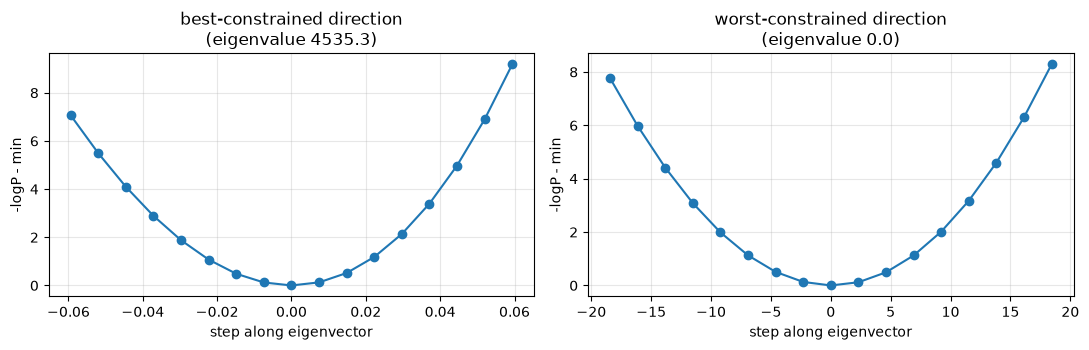

In [14]:
# =====================================================================
# THE REAL RUN: estimate p from the sky-marginalised likelihood, with uncertainties
# =====================================================================
BL = make_blocks(LFIT, beam_alms_PERTURBED_transformed)
ix = BL['ix']
ops = make_ops(ix)
print(f"LFIT={LFIT}  n_x={ix['n_x']} per frequency  rows/freq={B_PTG * len(BL['t_sel'])}  freqs={N_FREQS}")

_p0 = jnp.zeros(K_MODES)
t0 = time.time()
_ = ops['vg'](_p0, BL['blks'], BL['phc'], PRIOR_SIGMA_P)
print(f"first call (includes compile): {time.time() - t0:.1f}s")
t0 = time.time()
nlml_zero, _g0 = ops['vg'](_p0, BL['blks'], BL['phc'], PRIOR_SIGMA_P)
t_eval = time.time() - t0
print(f"one value+gradient evaluation: {t_eval:.2f}s   -> a {N_STARTS}-start optimisation is roughly "
      f"{N_STARTS * 40 * t_eval / 60:.1f} min")

print("\nMulti-start optimisation of -log P(y | p):")
sols = optimise(ops, BL['blks'], BL['phc'])
nlml_best, p_hat = sols[0][0], sols[0][1]
print(f"\nbest   p_hat = {np.round(p_hat, 5)}   -logP = {nlml_best:.3f}")
print(f"p = 0        -logP = {float(nlml_zero):.3f}   (improvement from calibrating: {float(nlml_zero) - nlml_best:.2f} nats)")
distinct = [s for s in sols if abs(s[0] - nlml_best) > 0.5]
if distinct:
  print(f"NOTE: {len(distinct)} start(s) ended in a different local optimum with higher -logP "
        f"(best of those: {distinct[0][0]:.3f}) - the likelihood is multi-modal here.")
else:
  print("All starts converged to the same optimum (single mode within the box).")

print("\nLaplace (Gaussian) posterior for p at the optimum:")
H, w_eig, V_eig, cov_p = laplace(ops, BL['blks'], BL['phc'], p_hat)
sd_p = np.sqrt(np.diag(cov_p))
print(f"  sigma(p_k)           = {np.round(sd_p, 5)}")
print(f"  prior sigma          = {PRIOR_SIGMA_P}")
print(f"  Hessian eigenvalues  = {np.round(w_eig, 1)}   (prior alone contributes {1 / PRIOR_SIGMA_P ** 2:.0f})")
sd_dir = 1.0 / np.sqrt(np.clip(w_eig, 1e-8, None))
print(f"  posterior sd along each eigen-direction = {np.round(sd_dir, 3)}   (prior sd = {PRIOR_SIGMA_P})")
print("  -> directions with sd << prior sd are measured by the data; sd comparable to the prior sd (or larger) are not identified.")

# profile of -logP along the best- and worst-constrained directions
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (name, j) in zip(axes, [("best-constrained direction", int(np.argmax(w_eig))),
                                ("worst-constrained direction", int(np.argmin(w_eig)))]):
  sig = 1.0 / np.sqrt(max(w_eig[j], 1e-8))
  half = min(4 * sig, BOUND_P)
  s_grid = np.linspace(-half, half, 17)
  prof = []
  for s in s_grid:
    pp = np.clip(p_hat + s * V_eig[:, j], -BOUND_P, BOUND_P)
    prof.append(float(ops['total'](jnp.asarray(pp), BL['blks'], BL['phc'], PRIOR_SIGMA_P)))
  ax.plot(s_grid, np.array(prof) - nlml_best, "o-")
  ax.set_title(f"{name}\n(eigenvalue {w_eig[j]:.1f})")
  ax.set_xlabel("step along eigenvector")
  ax.set_ylabel("-logP - min")
  ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


                                sky err l<=5 sky err l<=10 sky err l<=32  resid rms  beam shape err       -logP
p = 0  (no calibration)               0.4869        0.5236        0.5397      0.085          0.0300    33700.33
p = p_hat  (this solver)              0.2197        0.3046        0.3381      0.036          0.0085    33632.08
p = alm oracle (reference)            0.4881        0.5247        0.5407      0.084          0.0314    33700.48
TRUE beam (unattainable)              0.2172        0.3038        0.3374      0.036          0.0000         nan

p_hat    = [5.057  5.0947 5.1249 4.6621 3.948  4.0398 2.8202 2.5469]
p_oracle = [-0.0468 -0.047  -0.0465 -0.0472 -0.0451 -0.0644 -0.0511  0.0513]
(the oracle ignores observability, so p_hat need NOT match it; the overall-gain direction is unobservable by construction)


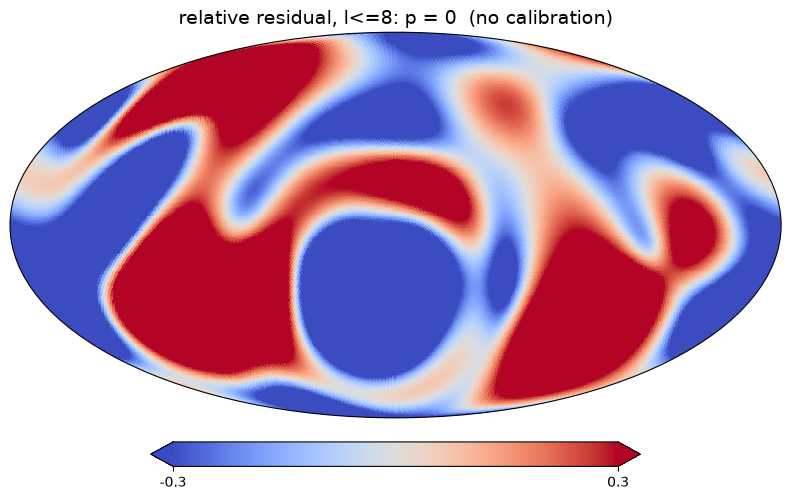

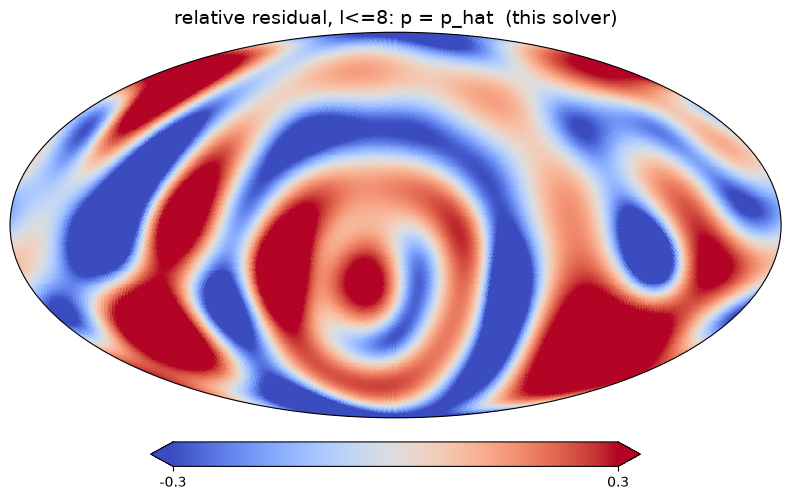

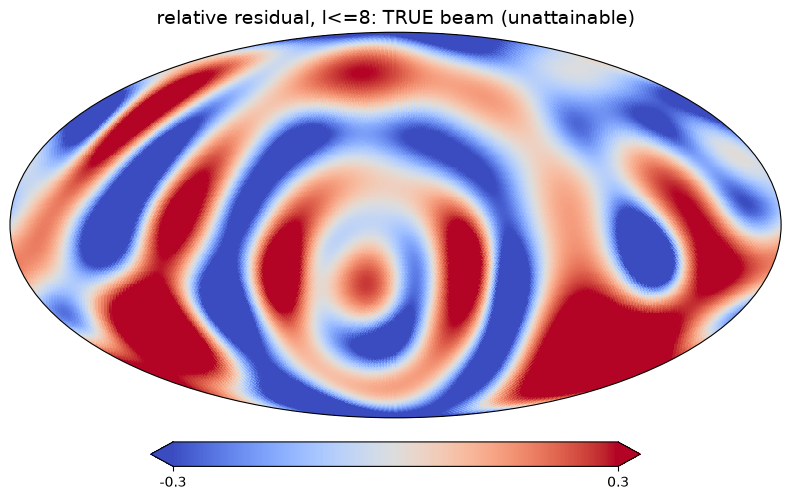

In [15]:
# =====================================================================
# DID IT HELP?  Compare against the references (this is a simulation, so truth is known)
#   * p = 0                 : the perturbed beam exactly as given (no calibration)
#   * p = p_hat             : this solver
#   * p = alm-space oracle  : best in-span fit to the true beam error (alm L2, ignores what the data can see)
#   * TRUE beam             : unattainable reference = how good the sky could be with the beam known
# Sky errors are for the SAME band-limited, marginalised posterior-mean sky in every row.
# =====================================================================
# oracle in-span coefficients (alm-space least squares, normal equations)
# sum_i (re_a re_b + im_a im_b) == Re sum_i conj(a_i) b_i, so no stacked real/imag copies are needed
_Mflat = mode_np.reshape(K_MODES, -1)
_err = (np.asarray(beam_alms_TRUE_transformed) - np.asarray(beam_alms_PERTURBED_transformed)).reshape(-1)
p_oracle = np.linalg.solve(np.real(_Mflat.conj() @ _Mflat.T), np.real(_Mflat.conj() @ _err))
del _Mflat, _err

BL_true = make_blocks(LFIT, beam_alms_TRUE_transformed)
x_true_lim = np.asarray(x_true_flat).reshape(N_FREQS, -1)[:, ix['pos']]          # (F, n_x)


def sky_solution(p, BLx):
  out = []
  for f in range(N_FREQS):
    blk = {k: v[f] for k, v in BLx['blks'].items()}
    xh, sd, rr = ops['post'](jnp.asarray(p), blk, BLx['phc'])
    out.append((np.asarray(xh), np.asarray(sd), float(rr)))
  return out


def band_err(sol, lmax_b):
  m = ix['lof'] <= lmax_b
  return np.mean([np.linalg.norm((sol[f][0] - x_true_lim[f])[m]) / np.linalg.norm(x_true_lim[f][m])
                  for f in range(N_FREQS)])


def beam_shape_err(p):
  """alm-space error of the NORMALISED beam b/norm(b) (the only thing the data can see)."""
  b = beam_alms_PERTURBED_transformed + jnp.tensordot(jnp.asarray(p), mode_tensor, axes=1)
  n = np.asarray(compute_norms_curr(b))
  bt = np.asarray(beam_alms_TRUE_transformed)
  nt = np.asarray(compute_norms_curr(beam_alms_TRUE_transformed))
  bn = np.asarray(b) / n[:, :, None, None]
  btn = bt / nt[:, :, None, None]
  shape = np.linalg.norm(bn - btn) / np.linalg.norm(btn)
  raw = np.linalg.norm(np.asarray(b) - bt) / np.linalg.norm(bt)
  return shape, raw


rows = [("p = 0  (no calibration)", np.zeros(K_MODES), BL),
        ("p = p_hat  (this solver)", p_hat, BL),
        ("p = alm oracle (reference)", p_oracle, BL),
        ("TRUE beam (unattainable)", np.zeros(K_MODES), BL_true)]
bands = [5, 10, LFIT]
print(f"{'':30s}" + "".join(f"{'sky err l<=' + str(b):>14s}" for b in bands)
      + f"{'resid rms':>11s}{'beam shape err':>16s}{'-logP':>12s}")
sols_sky = {}
for name, p, BLx in rows:
  sol = sky_solution(p, BLx)
  sols_sky[name] = sol
  if BLx is BL_true:
    shp = 0.0
    nl = float('nan')
  else:
    shp, _raw = beam_shape_err(p)
    nl = float(ops['total'](jnp.asarray(p), BL['blks'], BL['phc'], PRIOR_SIGMA_P))
  print(f"{name:30s}" + "".join(f"{band_err(sol, b):14.4f}" for b in bands)
        + f"{np.mean([s[2] for s in sol]):11.3f}{shp:16.4f}{nl:12.2f}")
print(f"\np_hat    = {np.round(p_hat, 4)}\np_oracle = {np.round(p_oracle, 4)}"
      f"\n(the oracle ignores observability, so p_hat need NOT match it; the overall-gain direction is unobservable by construction)")

# residual maps (f = 0) for the low-l sky
def _lowl_map(xlim, f=0):
  xf = np.zeros(oned_shape)
  xf[ix['pos']] = xlim
  flm = np.array(s2fft_unravel(jnp.asarray(xf), lmax)[0])
  flm[LMAP + 1:] = 0
  return np.asarray(s2fft.inverse_jax(jnp.asarray(flm), L=lmax + 1, spin=0, nside=nside,
                                      sampling="healpix", reality=True).real)

truth_map = _lowl_map(x_true_lim[0])
mask = np.abs(truth_map) > 0.05 * np.max(np.abs(truth_map))
for name in ["p = 0  (no calibration)", "p = p_hat  (this solver)", "TRUE beam (unattainable)"]:
  est_map = _lowl_map(sols_sky[name][0][0])
  rel = np.where(mask, (truth_map - est_map) / np.where(mask, truth_map, 1.0), np.nan)
  hp.projview(rel, title=f"relative residual, l<={LMAP}: {name}", min=-0.3, max=0.3, cmap="coolwarm")
  plt.show()


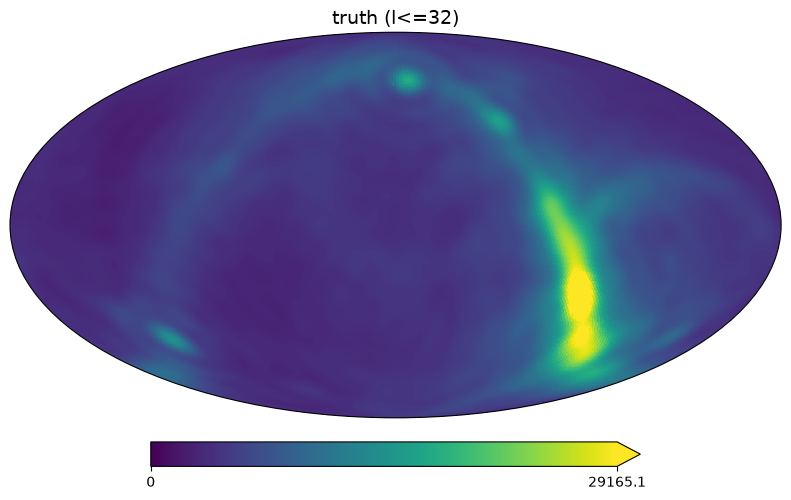

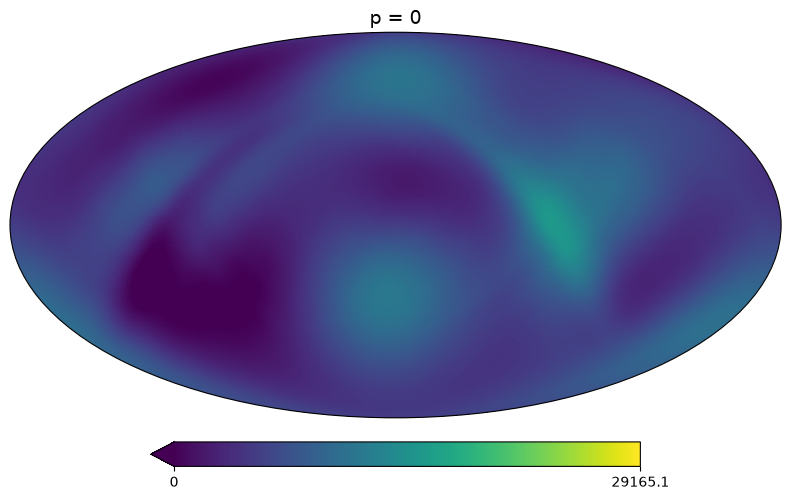

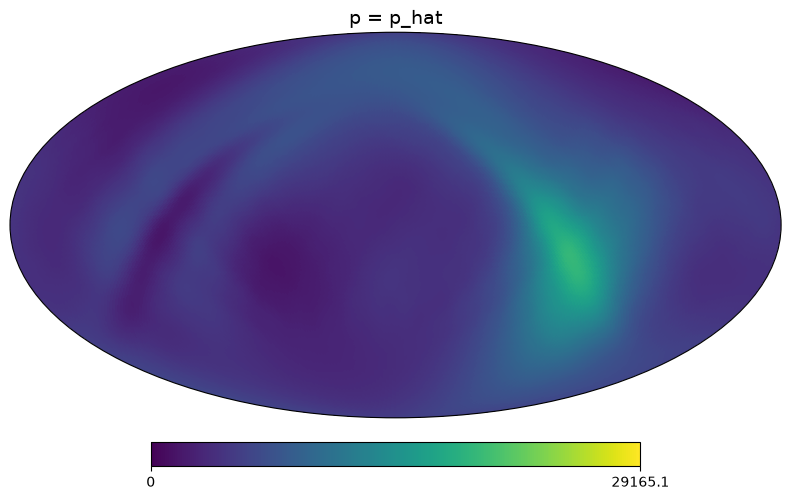

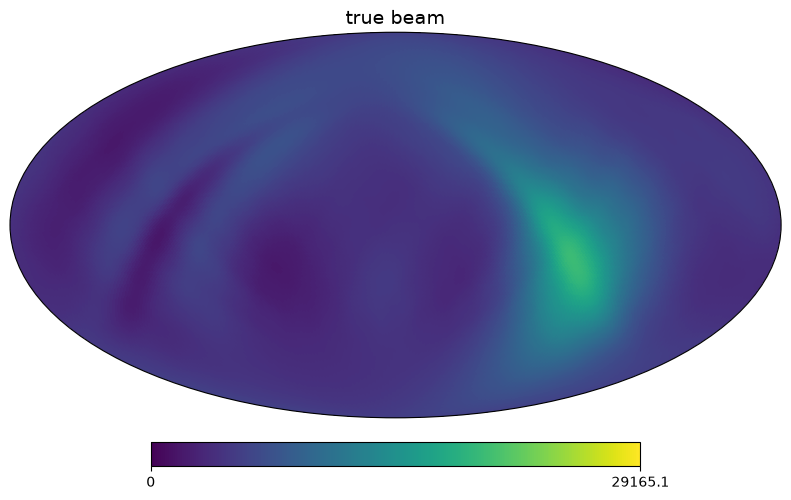

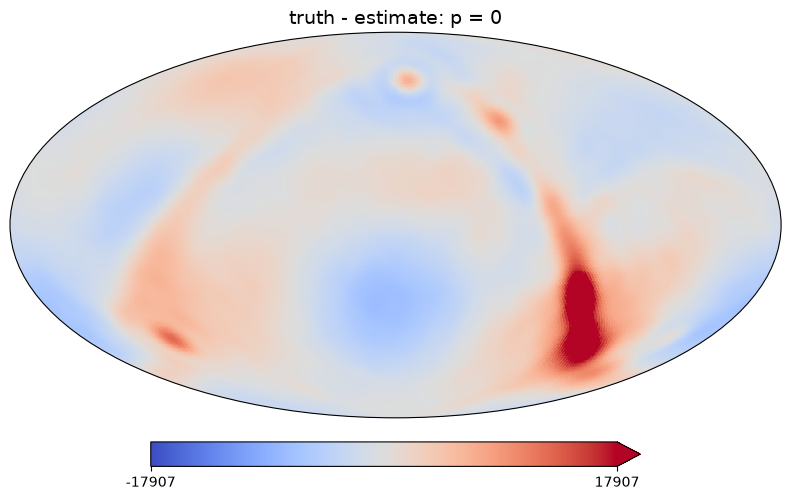

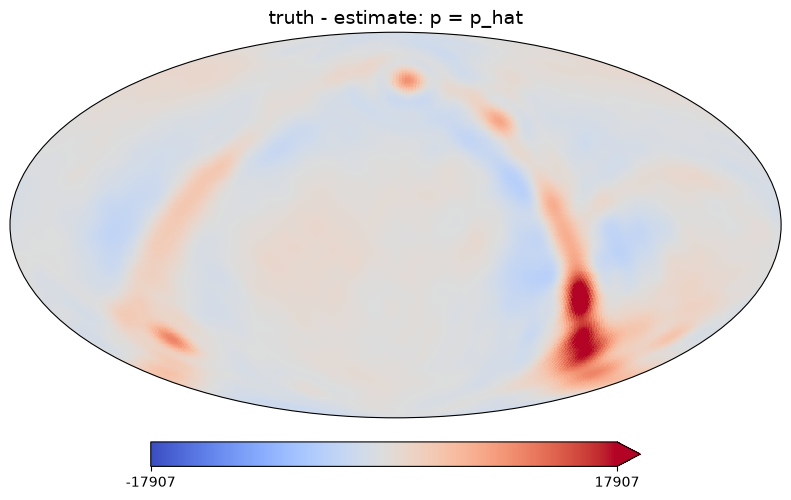

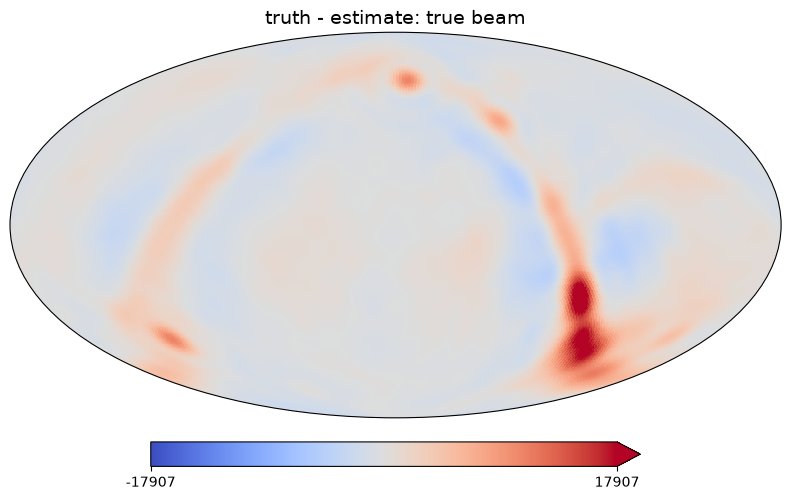

In [16]:
LCUT = LFIT   # band limit of the maps; the solver only constrains l <= LFIT

def _band_map(xlim, f=0, lcut=LCUT):
    xf = np.zeros(oned_shape)
    xf[ix['pos']] = xlim
    flm = np.array(s2fft_unravel(jnp.asarray(xf), lmax)[0])
    flm[lcut + 1:] = 0
    return np.asarray(s2fft.inverse_jax(jnp.asarray(flm), L=lmax + 1, spin=0, nside=nside,
                                        sampling="healpix", reality=True).real)

truth = _band_map(x_true_lim[0])
est0  = _band_map(sols_sky["p = 0  (no calibration)"][0][0])
estp  = _band_map(sols_sky["p = p_hat  (this solver)"][0][0])
estT  = _band_map(sols_sky["TRUE beam (unattainable)"][0][0])

vmax = np.percentile(truth, 99.5)
for name, m in [("truth (l<=%d)" % LCUT, truth),
                ("p = 0", est0), ("p = p_hat", estp), ("true beam", estT)]:
    hp.projview(m, title=name, min=0, max=vmax, cmap="viridis")
    plt.show()

# absolute residuals, same colour scale for all three
rmax = np.percentile(np.abs(truth - est0), 99)
for name, m in [("p = 0", est0), ("p = p_hat", estp), ("true beam", estT)]:
    hp.projview(truth - m, title=f"truth - estimate: {name}",
                min=-rmax, max=rmax, cmap="coolwarm")
    plt.show()

In [17]:
def _alm(m): return hp.map2alm(m, lmax=LCUT)
ell = hp.Alm.getlm(LCUT)[0]
At = _alm(truth)
print(" l-band    p=0    p_hat   true-beam   (relative error, per l band)")
for lo, hi in [(0,2),(3,4),(5,6),(7,8),(9,12),(13,LCUT)]:
    s = (ell >= lo) & (ell <= hi)
    n = np.linalg.norm(At[s])
    print(f" {lo:>2}-{hi:<2}   " + "   ".join(
        f"{np.linalg.norm((_alm(m) - At)[s]) / n:6.3f}" for m in (est0, estp, estT)))

 l-band    p=0    p_hat   true-beam   (relative error, per l band)
  0-2     0.265    0.126    0.135
  3-4     1.308    0.622    0.545
  5-6     1.024    0.882    0.905
  7-8     0.920    0.895    0.893
  9-12    0.935    0.925    0.923
 13-32    0.996    0.996    0.996


In [18]:
f = 0
sd  = sols_sky["TRUE beam (unattainable)"][f][1]
psd = np.asarray(BL_true['blks']['sq'][f])
lof = np.asarray(ix['lof'])
print(" l    fraction of prior variance removed by the data (true beam)")
for l in list(range(0, 13)) + [16, 24, 32, 48]:
    s = lof == l
    if s.any():
        print(f"{l:3d}   {1 - np.mean(sd[s]**2) / np.mean(psd[s]**2):6.3f}")

 l    fraction of prior variance removed by the data (true beam)
  0    0.987
  1    0.651
  2    0.754
  3    0.518
  4    0.583
  5    0.314
  6    0.031
  7    0.214
  8    0.009
  9    0.146
 10    0.003
 11    0.104
 12    0.001
 16    0.000
 24    0.000
 32    0.000


In [19]:
b = np.asarray(beam_alms_TRUE_transformed)[0, 0]          # pointing 0, freq 0: (L, M)
L, M = b.shape
l = np.arange(L)[:, None]; m = np.arange(M)[None, :] - (M - 1) // 2
even = ((l + m) % 2 == 0)
pw = np.abs(b) ** 2
print(" l   power/power(l=0)   share in even(l+m)")
for ll in range(0, 17):
    print(f"{ll:2d}   {pw[ll].sum() / pw[0].sum():10.3e}      {pw[ll][even[ll]].sum() / pw[ll].sum():5.2f}")

 l   power/power(l=0)   share in even(l+m)
 0    1.000e+00       1.00
 1    9.482e-01       0.60
 2    1.914e-01       0.27
 3    1.232e-01       0.59
 4    1.269e-04       0.64
 5    3.749e-02       0.46
 6    1.538e-06       0.49
 7    1.956e-02       0.52
 8    4.123e-07       0.50
 9    1.205e-02       0.49
10    3.019e-07       0.52
11    8.220e-03       0.50
12    4.392e-08       0.50
13    5.926e-03       0.50
14    1.140e-07       0.54
15    4.513e-03       0.50
16    9.628e-09       0.50


In [20]:
Mflat = mode_np.reshape(K_MODES, -1)
err = (np.asarray(beam_alms_TRUE_transformed) - np.asarray(beam_alms_PERTURBED_transformed)).reshape(-1)
G = np.real(Mflat.conj() @ Mflat.T); c = np.real(Mflat.conj() @ err)
p_or = np.linalg.solve(G, c)
print("fraction of beam-error energy inside the mode span: %.4f" % ((c @ p_or) / np.real(err.conj() @ err)))
for k in range(1, K_MODES + 1):
    Gk, ck = G[:k, :k], c[:k]
    print(f"  first {k} modes: {(ck @ np.linalg.solve(Gk, ck)) / np.real(err.conj() @ err):.4f}")
del Mflat, err

fraction of beam-error energy inside the mode span: 0.6898
  first 1 modes: 0.5862
  first 2 modes: 0.6718
  first 3 modes: 0.6832
  first 4 modes: 0.6896
  first 5 modes: 0.6897
  first 6 modes: 0.6898
  first 7 modes: 0.6898
  first 8 modes: 0.6898


In [21]:
from scipy.optimize import minimize
f = lambda p: beam_shape_err(p)[0]
r = minimize(f, np.zeros(K_MODES), method='Powell', options=dict(maxiter=300, xtol=1e-3, ftol=1e-5))
print("shape err: p=0 %.4f   best-in-span %.4f   p_hat %.4f" % (f(np.zeros(K_MODES)), r.fun, f(p_hat)))
print("shape-optimal p =", np.round(r.x, 4))

shape err: p=0 0.0300   best-in-span 0.0002   p_hat 0.0085
shape-optimal p = [6.27175234e+11 6.27314566e+11 6.26720978e+11 6.27029720e+11
 6.26980887e+11 6.23128974e+11 6.22388597e+11 6.46307963e+11]


In [22]:
jp = lambda p: float(ops['total'](jnp.asarray(p), BL['blks'], BL['phc'], 1e12))   # no prior penalty
nl_pert = jp(np.zeros(K_MODES))
nl_hat  = jp(p_hat)
nl_true = float(ops['total'](jnp.asarray(np.zeros(K_MODES)), BL_true['blks'], BL_true['phc'], 1e12))
nl_big  = jp(1e6 * np.ones(K_MODES))
print(f"-logP  perturbed beam (p=0): {nl_pert:.2f}")
print(f"-logP  p_hat               : {nl_hat:.2f}   (gain {nl_pert - nl_hat:.2f})")
print(f"-logP  TRUE beam           : {nl_true:.2f}   (gain {nl_pert - nl_true:.2f})")
print(f"-logP  large equal-weight p: {nl_big:.2f}")

-logP  perturbed beam (p=0): 33700.33
-logP  p_hat               : 33629.16   (gain 71.18)
-logP  TRUE beam           : 33638.73   (gain 61.60)
-logP  large equal-weight p: 33623.33


## Robustness tests

The strong result above (loose prior: p_hat reaches true-beam sky quality) has two weaknesses these cells test:

1. **Is it tied to the prior / band limit / mode count I happened to pick?** (`R1`: sensitivity sweep)
2. **Is it circular?** The modes are the SVD components of the *same* bowtie beam family the truth comes from, and the equal-weight sum of the modes is the true beam. A calibration basis built that way contains the answer. (`R2`/`R3`: blind basis.)
   The blind basis is built from the bowtie beams at channels **far from** the analysis channels (a margin is cut out around them), and the per-frequency mode weights come from the *known, perturbed* beam, never the truth. In that basis the large-p limit reproduces the perturbed beam, not the true one, so any gain has to be a real shape correction.

Every run below prints the same scorecard, including the p=0 and true-beam references, and the fraction of the beam-error energy the mode span can represent at all. Each fit takes a minute or two.

In [23]:
# =====================================================================
# R0: one self-contained function that fits p for ANY mode tensor / prior / band limit and scores it
# =====================================================================
import contextlib


@contextlib.contextmanager
def _swap_globals(**kw):
  g = globals()
  _missing = object()
  old = {k: g.get(k, _missing) for k in kw}
  g.update(kw)
  try:
    yield
  finally:
    for k, v in old.items():
      if v is _missing:
        g.pop(k, None)
      else:
        g[k] = v


def run_config(label, mt=None, sigma=None, bound=None, lfit=None, n_starts=2, maxiter=200, verbose=True):
  """Fit p by maximising the sky-marginalised likelihood for the given mode tensor `mt`
  (K, B, F, L, M), prior sigma, box bound and band limit, then score it against the truth."""
  mt = mode_tensor if mt is None else mt
  sigma = PRIOR_SIGMA_P if sigma is None else sigma
  bound = BOUND_P if bound is None else bound
  lfit = LFIT if lfit is None else lfit
  t_start = time.time()
  mnp = np.asarray(mt)
  K = mnp.shape[0]
  nkm = np.asarray(jax.vmap(compute_norms_curr)(mt))
  print(f"\n--- {label}:  K={K}  prior sigma={sigma}  bound={bound}  LFIT={lfit}")
  with _swap_globals(mode_tensor=mt, mode_np=mnp, nk_modes=nkm, K_MODES=K,
                     PRIOR_SIGMA_P=sigma, BOUND_P=bound):
    BLc = make_blocks(lfit, beam_alms_PERTURBED_transformed)
    BLt = make_blocks(lfit, beam_alms_TRUE_transformed)
    ixc = BLc['ix']
    opsc = make_ops(ixc)
    sols_c = optimise(opsc, BLc['blks'], BLc['phc'], n_starts=n_starts, verbose=verbose, maxiter=maxiter)
    p_hat_c = np.asarray(sols_c[0][1])
    zero = np.zeros(K)

    def nl(p, BLx):                               # -log P(y|p) WITHOUT the prior penalty
      return float(opsc['total'](jnp.asarray(p), BLx['blks'], BLx['phc'], 1e12))

    xt = np.asarray(x_true_flat).reshape(N_FREQS, -1)[:, ixc['pos']]

    def sky(p, BLx):
      out = []
      for f in range(N_FREQS):
        blk = {k: v[f] for k, v in BLx['blks'].items()}
        out.append(np.asarray(opsc['post'](jnp.asarray(p), blk, BLx['phc'])[0]))
      return out

    def band(sol, lmax_b):
      m = ixc['lof'] <= lmax_b
      return float(np.mean([np.linalg.norm((sol[f] - xt[f])[m]) / np.linalg.norm(xt[f][m])
                            for f in range(N_FREQS)]))

    s0, sh, st = sky(zero, BLc), sky(p_hat_c, BLc), sky(zero, BLt)

    def shape_err(p):
      b = beam_alms_PERTURBED_transformed + jnp.tensordot(jnp.asarray(p), mt, axes=1)
      n = np.asarray(compute_norms_curr(b))
      nt_ = np.asarray(compute_norms_curr(beam_alms_TRUE_transformed))
      bn = np.asarray(b) / n[:, :, None, None]
      btn = np.asarray(beam_alms_TRUE_transformed) / nt_[:, :, None, None]
      return float(np.linalg.norm(bn - btn) / np.linalg.norm(btn))

    Mflat = mnp.reshape(K, -1)
    err = (np.asarray(beam_alms_TRUE_transformed) - np.asarray(beam_alms_PERTURBED_transformed)).reshape(-1)
    G = np.real(Mflat.conj() @ Mflat.T)
    c = np.real(Mflat.conj() @ err)
    cap = float(c @ np.linalg.lstsq(G, c, rcond=None)[0] / np.real(err.conj() @ err))
    del Mflat, err

    _, w_eig, _, _ = laplace(opsc, BLc['blks'], BLc['phc'], p_hat_c)

    nl0, nlh, nlt = nl(zero, BLc), nl(p_hat_c, BLc), nl(zero, BLt)
    e5 = [band(s, 5) for s in (s0, sh, st)]
    e10 = [band(s, 10) for s in (s0, sh, st)]
    out = dict(label=label, K=K, sigma=sigma, lfit=lfit, gain=nl0 - nlh, gain_true=nl0 - nlt,
               e5=e5, e10=e10, shape0=shape_err(zero), shape=shape_err(p_hat_c), cap=cap,
               pnorm=float(np.linalg.norm(p_hat_c)), p_hat=p_hat_c,
               sd_dir=1.0 / np.sqrt(np.clip(w_eig, 1e-8, None)),
               n_distinct=len([s for s in sols_c if abs(s[0] - sols_c[0][0]) > 0.5]),
               secs=time.time() - t_start)
  fn = getattr(jax, "clear_caches", None)
  if fn is not None:
    fn()
  return out


def print_scorecard(rows, title):
  print("\n" + "=" * 118)
  print(title)
  print("=" * 118)
  print(f"{'config':32s}{'K':>3s}{'gain':>8s}{'(true)':>8s}{'err l<=5':>10s}{'err l<=10':>11s}"
        f"{'gap5':>7s}{'gap10':>7s}{'shape':>8s}{'span':>7s}{'|p|':>8s}{'bad starts':>11s}")
  for r in rows:
    gap5 = (r['e5'][0] - r['e5'][1]) / max(r['e5'][0] - r['e5'][2], 1e-12)
    gap10 = (r['e10'][0] - r['e10'][1]) / max(r['e10'][0] - r['e10'][2], 1e-12)
    print(f"{r['label']:32s}{r['K']:3d}{r['gain']:8.1f}{r['gain_true']:8.1f}"
          f"{r['e5'][1]:10.3f}{r['e10'][1]:11.3f}{gap5:7.0%}{gap10:7.0%}"
          f"{r['shape']:8.4f}{r['cap']:7.0%}{r['pnorm']:8.2f}{r['n_distinct']:11d}")
  r = rows[0]
  print(f"\nreferences (same for every row): err l<=5  p=0 {r['e5'][0]:.3f}   true beam {r['e5'][2]:.3f};   "
        f"err l<=10  p=0 {r['e10'][0]:.3f}   true beam {r['e10'][2]:.3f};   beam shape err at p=0 {r['shape0']:.4f}")
  print("gain  = -logP improvement over p=0 (prior term excluded);  (true) = the same for the TRUE beam")
  print("gap5/gap10 = fraction of the p=0 -> true-beam sky-error gap that p_hat closes")
  print("span  = fraction of the beam-error energy the mode span can represent at all (oracle projection)")
  print("bad starts = starts that ended in a worse local optimum (>0.5 nats)")
  for r in rows:
    print(f"  posterior sd along eigen-directions [{r['label']}]: {np.round(r['sd_dir'], 3)}   ({r['secs']:.0f}s)")


In [24]:
# =====================================================================
# R1: SENSITIVITY SWEEP on the original (own-SVD) modes
# Does the loose-prior result depend on sigma, the band limit, or how many modes we use?
# (~1.5 min per row)
# =====================================================================
SWEEP = [
    dict(label="tight prior sigma=0.1 (ref)", sigma=0.1, bound=0.5),
    dict(label="sigma=1", sigma=1.0, bound=100.0),
    dict(label="sigma=5 (baseline)", sigma=5.0, bound=100.0),
    dict(label="sigma=25", sigma=25.0, bound=100.0),
    dict(label="sigma=5, LFIT=24", sigma=5.0, bound=100.0, lfit=24),
    dict(label="sigma=5, first 4 modes only", sigma=5.0, bound=100.0, mt=mode_tensor[:4]),
]
rows_sweep = []
for cfg in SWEEP:
  rows_sweep.append(run_config(**cfg))
print_scorecard(rows_sweep, "R1: sensitivity of the sky-error gain to prior width, band limit and mode count (own-SVD modes)")



--- tight prior sigma=0.1 (ref):  K=8  prior sigma=0.1  bound=0.5  LFIT=32
  start 0: -logP =     33676.5809  |p| = 0.4128  (26 iters, 32 evals, 15.7s)
  start 1: -logP =     33676.5798  |p| = 0.4134  (31 iters, 39 evals, 19.1s)

--- sigma=1:  K=8  prior sigma=1.0  bound=100.0  LFIT=32
  start 0: -logP =     33644.9756  |p| = 3.2009  (57 iters, 74 evals, 39.4s)
  start 1: -logP =     33644.9869  |p| = 3.1859  (40 iters, 55 evals, 27.6s)

--- sigma=5 (baseline):  K=8  prior sigma=5.0  bound=100.0  LFIT=32
  start 0: -logP =     33632.1162  |p| = 12.0516  (72 iters, 90 evals, 47.8s)
  start 1: -logP =     33632.0759  |p| = 12.0779  (57 iters, 78 evals, 40.5s)

--- sigma=25:  K=8  prior sigma=25.0  bound=100.0  LFIT=32
  start 0: -logP =     33625.7548  |p| = 39.0324  (72 iters, 92 evals, 48.6s)
  start 1: -logP =     33625.6793  |p| = 34.7199  (46 iters, 71 evals, 34.1s)

--- sigma=5, LFIT=24:  K=8  prior sigma=5.0  bound=100.0  LFIT=24
  start 0: -logP =     33673.4555  |p| = 11.9872  

In [25]:
# =====================================================================
# R2: builder for ANY mode basis (the same pipeline as the mode cell above),
#     plus the BLIND basis constructor
# =====================================================================
def build_mode_tensor(weights_fk, modes_kp, desc=""):
  """rotate each mode map through the pointings -> SHT -> FK5 rotation -> weight per frequency.
  weights_fk: (F, K), modes_kp: (K, NPIX).  Returns (K, B, F, L, M), the same layout as `mode_tensor`."""
  K = modes_kp.shape[0]
  rotated = [rotate_bowtie(modes_kp, elaz) for elaz in tqdm(elaz_pointings, desc=f"rotate {desc}")]
  mf = np.stack(rotated)                       # (B, K, NPIX)
  mf[..., npix // 2:] = 0.0
  per_b = []
  for b_idx in tqdm(range(mf.shape[0]), desc=f"SHT {desc}"):
    per_b.append(np.stack([
        s2fft.forward(np.ascontiguousarray(mf[b_idx, k]), L=lmax + 1, spin=0, nside=nside,
                      sampling="healpix", reality=True) for k in range(K)]))
  alms = jnp.array(np.stack(per_b))            # (B, K, L, M)
  fk5 = jax.jit(jax.vmap(jax.vmap(topo2fk5)))(alms)
  return jnp.einsum("fk, bklm -> kbflm", jnp.asarray(weights_fk), fk5)


def blind_mode_tensor(margin, n_modes=None):
  """Modes from an SVD of the bowtie beams at channels FAR from the analysis channels
  (channels FREQ_START-margin .. FREQ_END+margin are left out). Per-frequency weights are the
  projection of the KNOWN perturbed beam onto those modes, so the true beam is never used."""
  n_modes = N_MODES if n_modes is None else n_modes
  bm_all = bowtie["bm"]
  n_tot = bm_all.shape[0]
  lo, hi = max(0, FREQ_START - margin), min(n_tot, FREQ_END + margin)
  keep = np.ones(n_tot, dtype=bool)
  keep[lo:hi] = False
  print(f"blind basis: margin {margin} -> channels {lo}..{hi - 1} excluded, SVD of the remaining {int(keep.sum())} of {n_tot} channels")
  _, s_o, v_o = np.linalg.svd(bm_all[keep], full_matrices=False)
  v_blind = v_o[:n_modes]                                          # unit-norm spatial modes
  w_fk = np.asarray(base_bowtie_multi_PERTURBED) @ v_blind.T       # (F, K)
  return build_mode_tensor(w_fk, v_blind, desc=f"blind m={margin}")


CHECK_BUILDER = True      # rebuild the ORIGINAL modes with the new builder and compare (takes as long as the mode cell)
if CHECK_BUILDER:
  _mt_chk = build_mode_tensor(u_slice, v_slice, desc="check")
  _rel_chk = float(np.linalg.norm(np.asarray(_mt_chk) - np.asarray(mode_tensor)) / np.linalg.norm(np.asarray(mode_tensor)))
  print(f"builder self-check: rebuilt mode_tensor vs the one from the mode cell: rel. diff = {_rel_chk:.2e}   (expect ~1e-10 or smaller)")
  assert _rel_chk < 1e-6, "the builder does not reproduce the original mode tensor - do not trust the blind-basis results"
  del _mt_chk


rotate check:   0%|          | 0/20 [00:00<?, ?it/s]

SHT check:   0%|          | 0/20 [00:00<?, ?it/s]

builder self-check: rebuilt mode_tensor vs the one from the mode cell: rel. diff = 0.00e+00   (expect ~1e-10 or smaller)


In [26]:
# =====================================================================
# R3: BLIND-BASIS TEST
# Same solver, same sigma=5 / bound 100, but the modes come from beams at OTHER frequencies and the
# weights from the perturbed beam. The true beam is not inside this basis by construction.
# BLIND_MARGINS: how many channels around the analysis channels are cut out of the SVD
# (small = the basis still contains a near copy of the truth's shape, large = a harder test).
# =====================================================================
BLIND_MARGINS = [3, 20, 60]
rows_blind = [rows_sweep[2]] if 'rows_sweep' in globals() else [run_config("own-SVD modes, sigma=5", sigma=5.0, bound=100.0)]
for mg in BLIND_MARGINS:
  mt_b = blind_mode_tensor(mg)
  rows_blind.append(run_config(f"BLIND basis, margin {mg}", mt=mt_b, sigma=5.0, bound=100.0))
  del mt_b
print_scorecard(rows_blind, "R3: blind basis (true beam NOT in the span) vs the own-SVD basis")
print("""
How to read this:
  * If the BLIND rows keep a gap5/gap10 close to the own-SVD row, the calibration works without the answer in the basis.
  * If they fall to the level of the tight-prior row (or below), the own-SVD result was mostly circular.
  * 'span' tells you how much of the beam error a basis can represent in the first place; a low 'span' caps the gain
    whatever the optimiser does.  If gain stays near 0 and the starts disagree, the fit is not identifying anything.
""")


blind basis: margin 3 -> channels 0..6 excluded, SVD of the remaining 195 of 202 channels


rotate blind m=3:   0%|          | 0/20 [00:00<?, ?it/s]

SHT blind m=3:   0%|          | 0/20 [00:00<?, ?it/s]


--- BLIND basis, margin 3:  K=8  prior sigma=5.0  bound=100.0  LFIT=32
  start 0: -logP =     33631.9759  |p| = 11.9816  (58 iters, 77 evals, 39.9s)
  start 1: -logP =     33631.9007  |p| = 11.9969  (57 iters, 79 evals, 41.3s)
blind basis: margin 20 -> channels 0..23 excluded, SVD of the remaining 178 of 202 channels


rotate blind m=20:   0%|          | 0/20 [00:00<?, ?it/s]

SHT blind m=20:   0%|          | 0/20 [00:00<?, ?it/s]


--- BLIND basis, margin 20:  K=8  prior sigma=5.0  bound=100.0  LFIT=32
  start 0: -logP =     33632.0648  |p| = 12.3186  (74 iters, 93 evals, 47.9s)
  start 1: -logP =     33632.1304  |p| = 12.1843  (65 iters, 91 evals, 48.5s)
blind basis: margin 60 -> channels 0..63 excluded, SVD of the remaining 138 of 202 channels


rotate blind m=60:   0%|          | 0/20 [00:00<?, ?it/s]

SHT blind m=60:   0%|          | 0/20 [00:00<?, ?it/s]


--- BLIND basis, margin 60:  K=8  prior sigma=5.0  bound=100.0  LFIT=32
  start 0: -logP =     33637.6527  |p| = 11.7739  (80 iters, 98 evals, 50.8s)
  start 1: -logP =     33637.6528  |p| = 11.7740  (77 iters, 104 evals, 53.9s)

R3: blind basis (true beam NOT in the span) vs the own-SVD basis
config                            K    gain  (true)  err l<=5  err l<=10   gap5  gap10   shape   span     |p| bad starts
sigma=5 (baseline)                8    71.2    61.6     0.220      0.305    99%   100%  0.0085    69%   12.08          0
BLIND basis, margin 3             8    71.3    61.6     0.220      0.305    99%   100%  0.0084    69%   12.00          0
BLIND basis, margin 20            8    71.3    61.6     0.220      0.305    99%    99%  0.0086    69%   12.32          0
BLIND basis, margin 60            8    65.5    61.6     0.215      0.300   101%   102%  0.0088    69%   11.77          0

references (same for every row): err l<=5  p=0 0.487   true beam 0.217;   err l<=10  p=0 0.524   t

In [27]:
print("p_hat map: min %.0f, fraction negative %.3f   |   truth map min %.0f" % (estp.min(), (estp < 0).mean(), truth.min()))

p_hat map: min 1509, fraction negative 0.000   |   truth map min 2319


In [28]:
f = 0
xt = x_true_lim[f]; xh = sols_sky["TRUE beam (unattainable)"][f][0]
lof = np.asarray(ix['lof']); e2 = (xh - xt) ** 2; tot = e2.sum()
for lo, hi in [(0, 2), (3, 5), (6, 10), (11, LFIT)]:
    s = (lof >= lo) & (lof <= hi)
    print(f"l {lo:2d}-{hi:2d}: {e2[s].sum() / tot:6.1%} of squared error   "
          f"(even {e2[s & (lof % 2 == 0)].sum() / tot:5.1%}, odd {e2[s & (lof % 2 == 1)].sum() / tot:5.1%})")

l  0- 2:  17.2% of squared error   (even 10.9%, odd  6.3%)
l  3- 5:  21.2% of squared error   (even  7.4%, odd 13.8%)
l  6-10:  40.9% of squared error   (even 33.0%, odd  7.9%)
l 11-32:  20.7% of squared error   (even 11.2%, odd  9.5%)
